# 03 · Task 1 Loan-Amount Regression & Part E Deployable Scoring Service

**Owner:** P3 · Bernard (backed by shared `src/` pipeline)
**Scope:** Exploratory skewness of `Total_Amount` & `duration`, Task 1 regression comparison (`mean`, `ols`, `ridge`, `lasso`, `decision_tree_reg`, `lightgbm_reg`, `lit_linear`) evaluated on both log and original currency scales, residual diagnostics, feature interpretation, and the Part E `score_application()` service with top-3 plain-language reasons and 1,000-call latency benchmarking.

In [1]:
import sys
from pathlib import Path

ROOT = Path.cwd().resolve()
if not (ROOT / "src").exists() and (ROOT.parent / "src").exists():
    ROOT = ROOT.parent
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from src import config as C
from src.evaluation import regression_metrics
from src.models import build_estimator
from src.processing import TargetLogScaler, get_feature_lists, load_features, make_preprocessor
from src.serving import REQUIRED_APPLICATION_FIELDS, benchmark_latency, score_application
from src.training import fit_and_save_deployment_artifacts, run_cv

## 1. Loan Amount (`Total_Amount`) & Duration Distributions

       amount_local  log_amount_local   duration
count  6.865400e+04         68654.000  68654.000
mean   1.483683e+04             8.575      8.545
std    1.416499e+05             1.264     13.343
min    2.000000e+00             1.099      1.000
25%    2.295000e+03             7.739      7.000
50%    5.249000e+03             8.566      7.000
75%    1.145000e+04             9.346      7.000
max    2.300000e+07            16.951   1096.000


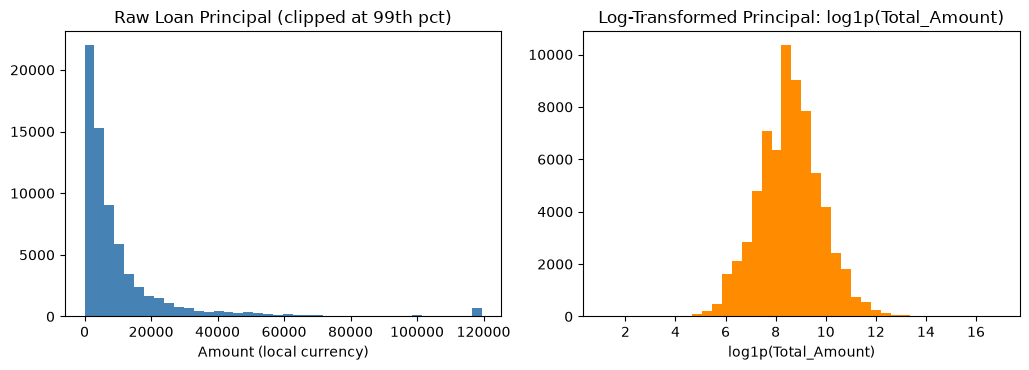

In [2]:
df = load_features()
train_df = df[df["split"] == "train"].copy()
train_df["amount_local"] = np.expm1(train_df["log_amount_local"])

print(train_df[["amount_local", "log_amount_local", "duration"]].describe().round(3))

fig, axes = plt.subplots(1, 2, figsize=(10.5, 3.8))
axes[0].hist(train_df["amount_local"].clip(upper=train_df["amount_local"].quantile(0.99)), bins=40, color="steelblue")
axes[0].set_title("Raw Loan Principal (clipped at 99th pct)")
axes[0].set_xlabel("Amount (local currency)")
axes[1].hist(train_df["log_amount_local"], bins=40, color="darkorange")
axes[1].set_title("Log-Transformed Principal: log1p(Total_Amount)")
axes[1].set_xlabel("log1p(Total_Amount)")
plt.tight_layout()
plt.show()

## 2. Task 1 Model Comparison (`fold_group` & `temporal`)

In [3]:
models_t1 = ["mean", "ols", "ridge", "lasso", "decision_tree_reg", "lightgbm_reg", "lit_linear"]
preds_t1 = {}
reg_rows = []

for m in models_t1:
    p_df = run_cv(df, model_name=m, task="task1", scheme="fold_group", save_preds=True)
    preds_t1[m] = p_df
    met = regression_metrics(p_df["y_true"], p_df["y_pred"])
    reg_rows.append({"model": m, "scheme": "fold_group", **met})

for m in ["mean", "ridge", "lightgbm_reg"]:
    p_df = run_cv(df, model_name=m, task="task1", scheme="temporal", save_preds=True)
    met = regression_metrics(p_df["y_true"], p_df["y_pred"])
    reg_rows.append({"model": m, "scheme": "temporal", **met})

pd.DataFrame(reg_rows).round(4)

,model,scheme,rmse_orig,mae_orig,rmse_log,mae_log,r2_log,median_abs_error_orig
0,mean,fold_group,1275.1550,109.7772,1.2097,0.9435,-0.0001,33.0867
1,ols,fold_group,2088.9364,122.3873,1.1094,0.8719,0.1588,29.2076
2,ridge,fold_group,1745.0921,110.7954,1.1115,0.8741,0.1556,29.2480
3,lasso,fold_group,1896.2902,119.3443,1.1240,0.8864,0.1366,30.1695
4,decision_tree_reg,fold_group,949.8851,92.0695,1.0894,0.8480,0.1889,29.0749
5,lightgbm_reg,fold_group,1113.7245,93.1966,1.0763,0.8353,0.2083,28.6386
6,lit_linear,fold_group,1765.3736,112.0601,1.1146,0.8759,0.1509,29.2917
7,mean,temporal,2242.2382,404.9452,1.5402,1.0350,-0.2675,27.5042
8,ridge,temporal,4189.9484,503.1633,1.1693,0.9441,0.2695,74.1976
9,lightgbm_reg,temporal,1841.9873,311.1714,0.8501,0.5782,0.6139,28.1346


**Reading:** the target is now the loan amount in **USD** (D-18), so `rmse_orig` and `mae_orig` are dollars. Predictions are clipped to the range of training amounts, which ended the billion-sized errors of the first version. On the log scale every model beats the mean (best: LightGBM, R² 0.21 by customer, 0.61 on 2023+ loans). On the dollar scale the linear models are *worse* than the mean (RMSE 1,750–2,090 vs 1,275): amounts are heavy-tailed, and a small error in log space becomes a large error in dollars for big loans. The pruned tree and LightGBM have the lowest dollar errors, so LightGBM sets limits in the scorer. Median absolute error is about USD 29 for every model, against a median loan of about USD 47.

## 3. Residual Diagnostics & Feature Importance

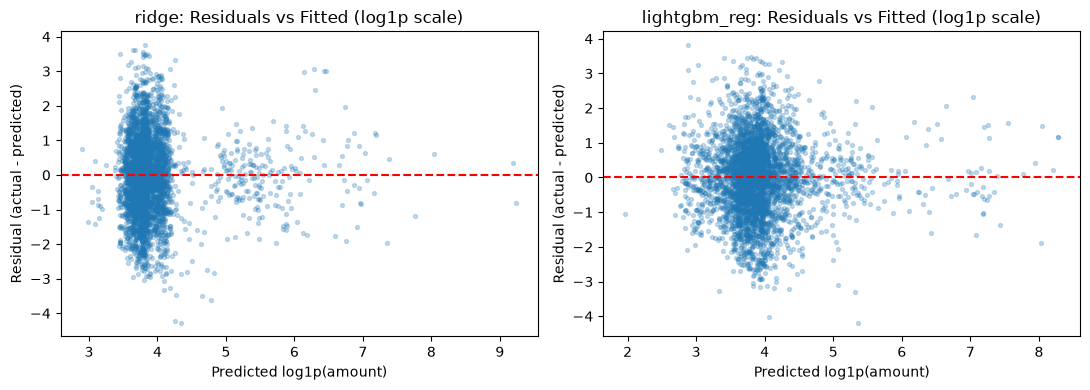

,feature,importance
4,num__n_past_loans,1759
6,num__n_past_labelled,1466
12,num__disb_dom,1160
1,num__Lender_portion_Funded,1122
5,num__days_since_last_loan,1068
10,num__disb_month,870
11,num__disb_dow,582
0,num__duration,333
21,cat__loan_type_Type_10,76
20,cat__loan_type_Type_1,75


In [4]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
for ax, m in zip(axes, ["ridge", "lightgbm_reg"]):
    p_df = preds_t1[m]
    yt_log = np.log1p(p_df["y_true"].to_numpy())
    yp_log = np.log1p(np.maximum(0.0, p_df["y_pred"].to_numpy()))
    resid = yt_log - yp_log
    idx = np.random.default_rng(C.SEED).choice(len(resid), size=min(4000, len(resid)), replace=False)
    ax.scatter(yp_log[idx], resid[idx], alpha=0.25, s=8)
    ax.axhline(0.0, color="red", linestyle="--")
    ax.set_title(f"{m}: Residuals vs Fitted (log1p scale)")
    ax.set_xlabel("Predicted log1p(amount)")
    ax.set_ylabel("Residual (actual - predicted)")
plt.tight_layout()
plt.show()

# Feature importances from LightGBM regressor fitted on training split
num_t1, cat_t1 = get_feature_lists("task1")
pre = make_preprocessor("task1", sparse_output=False)
X_tr = pre.fit_transform(train_df[num_t1 + cat_t1])
y_tr = TargetLogScaler().fit_transform(np.expm1(train_df["log_amount_usd"].to_numpy()))  # Task 1 target is USD (D-18)
lgb_reg = build_estimator("lightgbm_reg", task="task1").fit(X_tr, y_tr)
imp = pd.DataFrame({
    "feature": pre.get_feature_names_out(),
    "importance": lgb_reg.feature_importances_,
}).sort_values("importance", ascending=False).head(12)
imp

## 4. Part E Deployable Scoring Service (`src/serving/`) & Latency Benchmark

In [5]:
print("Required application payload specification:")
display(pd.DataFrame([
    {"field": k, "type": v[0], "required": v[2], "description": v[1]}
    for k, v in REQUIRED_APPLICATION_FIELDS.items()
]))

# Save calibrated Task 2 classifier + LightGBM Task 1 limit regressor
paths = fit_and_save_deployment_artifacts(df, clf_model="logreg", reg_model="lightgbm_reg")
print("Saved deployment artifacts:", paths)

kenya_repeat = {
    "customer_id": "KEN_DEMO_101",
    "country_id": "Kenya",
    "lender_id": "267278",
    "loan_type": "Type_1",
    "Total_Amount": 5000.0,
    "duration": 7.0,
    "disbursement_date": "2023-06-12",
    "New_versus_Repeat": "Repeat Loan",
    "n_past_loans": 8,
    "days_since_last_loan": 14.0,
    "n_past_labelled": 7,
    "n_past_defaults": 0,
}
ghana_new = {
    "customer_id": "GHA_DEMO_202",
    "country_id": "Ghana",
    "lender_id": "UNSEEN_GH_LENDER",
    "loan_type": "Type_3",
    "Total_Amount": 350.0,
    "duration": 30.0,
    "disbursement_date": "2023-02-15",
    "New_versus_Repeat": "New Loan",
    "n_past_loans": 0,
}

print("\nKenya Repeat Applicant Decision:", score_application(kenya_repeat))
print("Ghana New Applicant Decision:", score_application(ghana_new))

latency = benchmark_latency(n_calls=1000)
pd.DataFrame([latency]).round(3)

Required application payload specification:


,field,type,required,description
0,customer_id,str,True,Borrower identifier
1,country_id,str,True,'Kenya' or 'Ghana'
2,lender_id,str,True,Funding lender identifier
3,loan_type,str,True,"Loan product, e.g. 'Type_1'"
4,Total_Amount,float,True,Requested principal in local currency (KES or ...
5,duration,float,True,"Requested term in days, > 0"
6,disbursement_date,str,True,"Application date, YYYY-MM-DD"
7,New_versus_Repeat,str,True,'New Loan' or 'Repeat Loan'
8,Lender_portion_Funded,float,False,"Lender's share of the loan, 0-1 (default 0.30,..."
9,n_lenders_on_loan,int,False,Lenders funding this loan (default 1)


Saved deployment artifacts: {'clf_path': WindowsPath('C:/Users/berna/Documents/Ashesi/Machine Learning/Prosit 2/artifacts/task2_clf.joblib'), 'reg_path': WindowsPath('C:/Users/berna/Documents/Ashesi/Machine Learning/Prosit 2/artifacts/task1_reg.joblib')}

Kenya Repeat Applicant Decision: {'customer_id': 'KEN_DEMO_101', 'probability_of_default': 0.011098, 'threshold': 0.019435, 'decision': 'limit', 'requested_amount': 5000.0, 'recommended_limit': 4386.98, 'currency': 'KES', 'top_3_reasons': ['You have few earlier loans with us', 'Loans through this lender have a higher rate of missed repayments', 'The time since your last loan'], 'needs_review': False, 'review_flags': [], 'latency_ms': 173.847}


Ghana New Applicant Decision: {'customer_id': 'GHA_DEMO_202', 'probability_of_default': 0.088893, 'threshold': 0.019435, 'decision': 'decline', 'requested_amount': 350.0, 'recommended_limit': 0.0, 'currency': 'GHS', 'top_3_reasons': ['You have few earlier loans with us', 'This is your first loan with us, so there is no repayment record yet', 'The repayment period is longer than most loans we see repaid'], 'needs_review': True, 'review_flags': ['Model trained on Kenya loans only; Ghana scores are unvalidated', 'Lender not seen in training data', 'Loan product not seen in training data'], 'latency_ms': 49.688}


,n_calls,median_ms,p95_ms,mean_ms,min_ms,max_ms
0,1000,46.386,52.168,44.609,29.38,73.813
